In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [75]:
df = pd.read_csv("used_cars_data.csv")
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ', '_')
df.columns = df.columns.str.replace('(', '')
df.columns = df.columns.str.replace(')', '')
df.head()

,s.no.,name,location,year,kilometers_driven,fuel_type,transmission,owner_type,mileage,engine,power,seats,new_price,price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


<Axes: xlabel='price', ylabel='Density'>

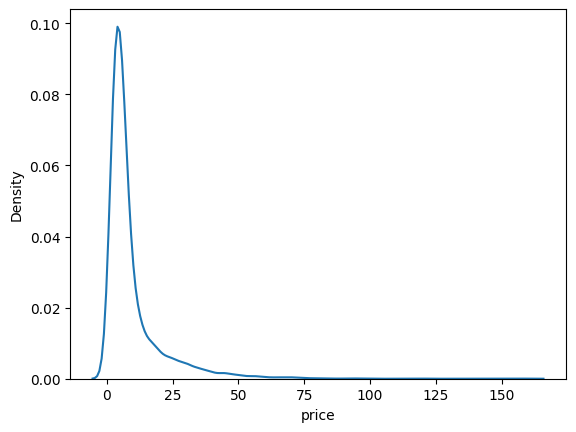

In [76]:
sns.kdeplot(df['price'])

<Axes: xlabel='price', ylabel='Count'>

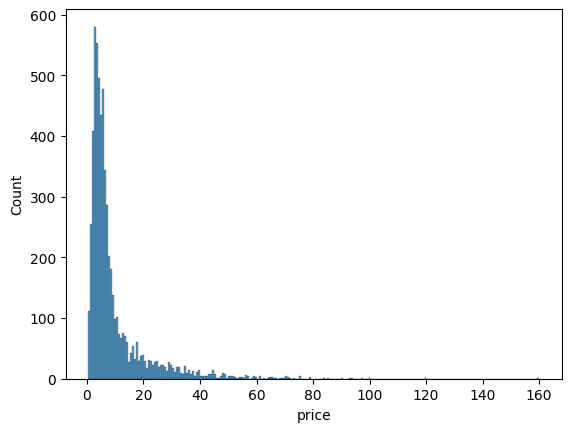

In [77]:
sns.histplot(df['price'])

In [78]:
import re

# Function to convert mileage to km/L and extract the numerical part
def convert_to_kmpl(mileage):
    mileage = str(mileage).strip()  # Ensure mileage is treated as a string and remove extra spaces

    # Check if the mileage contains 'km/kg' and convert it
    if 'km/kg' in mileage.lower():
        # Extract the numerical part before 'km/kg'
        match = re.match(r"([0-9.]+)\s*km/kg", mileage, re.IGNORECASE)
        if match:
            km_per_kg = float(match.group(1))
            return km_per_kg * 0.74  # Convert to km/L assuming fuel density of 0.74 kg/L
        else:
            return None  # Return None if the conversion is not valid

    # Check if the mileage contains 'kmpl'
    elif 'kmpl' in mileage.lower():
        # Extract the numerical part before 'kmpl'
        match = re.match(r"([0-9.]+)\s*kmpl", mileage, re.IGNORECASE)
        if match:
            return float(match.group(1))  # Already in km/L
        else:
            return None  # Return None if the conversion is not valid

    # If the string is not recognized, return None
    return None

# Apply the conversion function to the 'mileage' column
df['mileage'] = df['mileage'].apply(convert_to_kmpl)

# Show the first few rows of the updated dataframe
df.head()


,s.no.,name,location,year,kilometers_driven,fuel_type,transmission,owner_type,mileage,engine,power,seats,new_price,price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,19.684,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.670,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.200,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.770,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.200,1968 CC,140.8 bhp,5.0,NaN,17.74


<Axes: xlabel='mileage', ylabel='Density'>

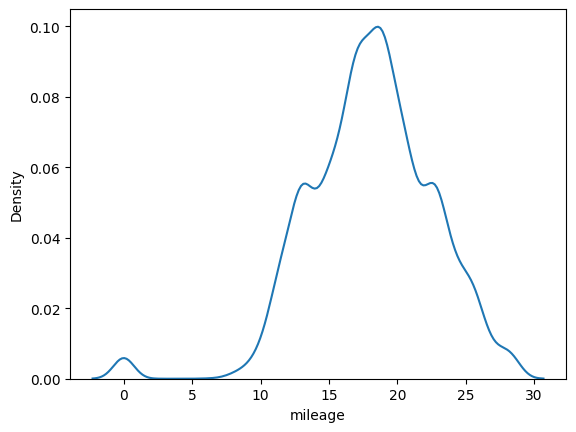

In [79]:
sns.kdeplot(df['mileage'])

<Axes: xlabel='mileage', ylabel='Count'>

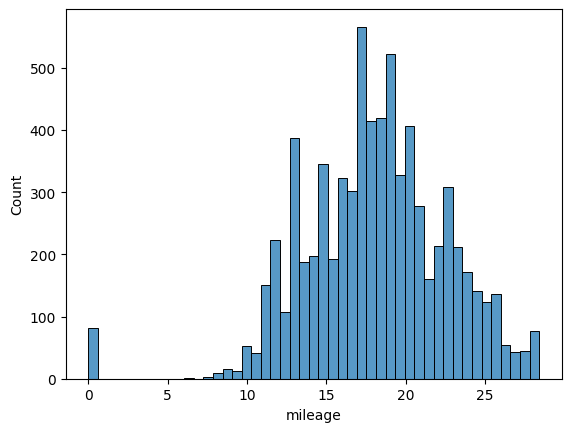

In [80]:
sns.histplot(df['mileage'])

In [81]:
#remove "CC" from all elements in engine so 998 CC -> 998
df['engine'] = df['engine'].str.replace('CC', '')
df['engine'] = df['engine'].str.strip()
#convert to float
df['engine'] = df['engine'].astype(float)


<Axes: xlabel='engine', ylabel='Density'>

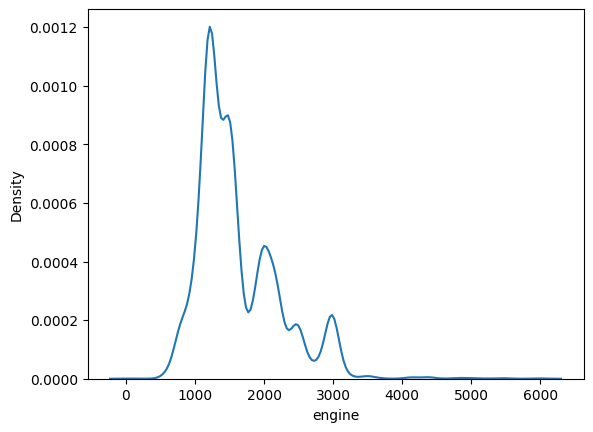

In [82]:
sns.kdeplot(df['engine'])

<Axes: xlabel='engine', ylabel='Count'>

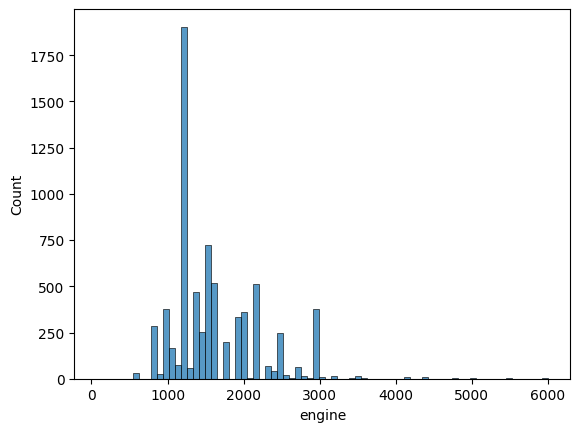

In [83]:
sns.histplot(df['engine'])

In [84]:
df.skew(numeric_only=True)

,0
s.no.,0.000000
year,-0.839816
kilometers_driven,61.582575
mileage,-0.526214
engine,1.412413
seats,1.902262
price,3.335232


In [85]:
df[["kilometers_driven", "engine", "seats", "price"]] = df[["kilometers_driven", "engine", "seats", "price"]].apply(lambda x: np.log1p(x))

In [86]:
df.skew(numeric_only=True)

,0
s.no.,0.000000
year,-0.839816
kilometers_driven,-1.298242
mileage,-0.526214
engine,0.302524
seats,0.631962
price,0.754372


<Axes: xlabel='price', ylabel='Density'>

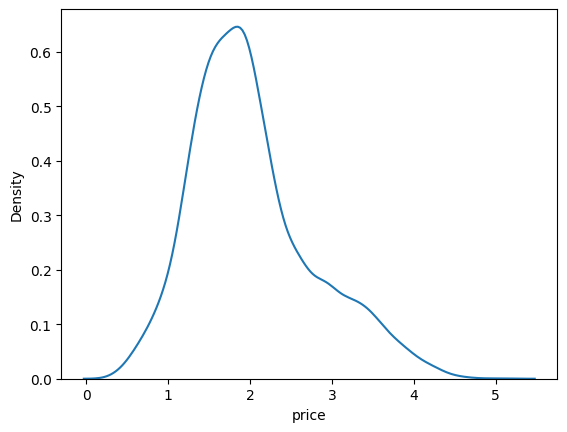

In [87]:
sns.kdeplot(df['price'])

<Axes: >

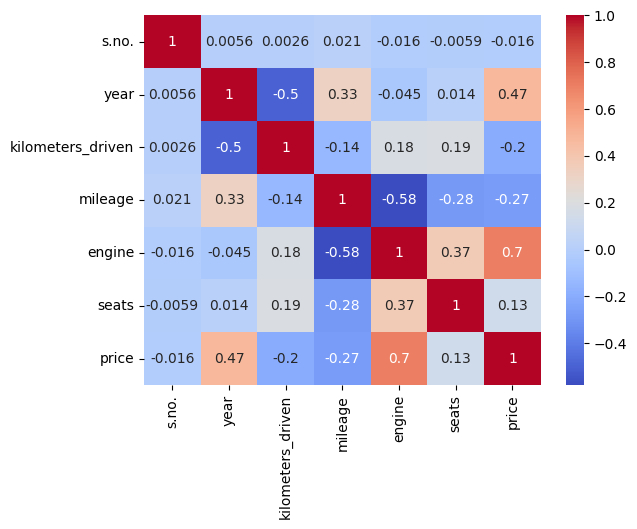

In [88]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm')

In [89]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df[["price", 'mileage', 'engine','power']].dropna()

# Convert 'power' to numeric after removing 'bhp' and handling potential errors
X['power'] = X['power'].astype(str).str.replace('bhp', '', regex=False).str.strip()
X['power'] = pd.to_numeric(X['power'], errors='coerce')
X = X.dropna() # Drop rows where conversion to numeric failed

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_data

,feature,VIF
0,price,23.232226
1,mileage,23.413245
2,engine,47.026163
3,power,19.847382


<Axes: xlabel='engine', ylabel='price'>

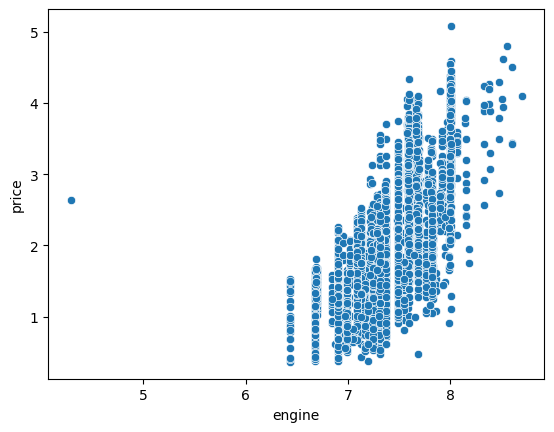

In [90]:
sns.scatterplot(data=df, x="engine", y="price")

<Axes: xlabel='fuel_type', ylabel='price'>

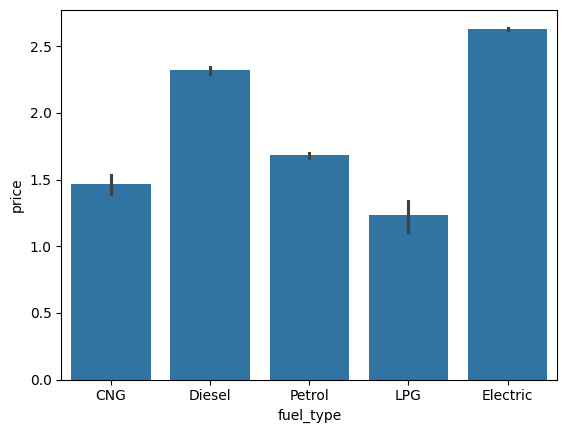

In [92]:
sns.barplot(data=df, x="fuel_type", y="price")

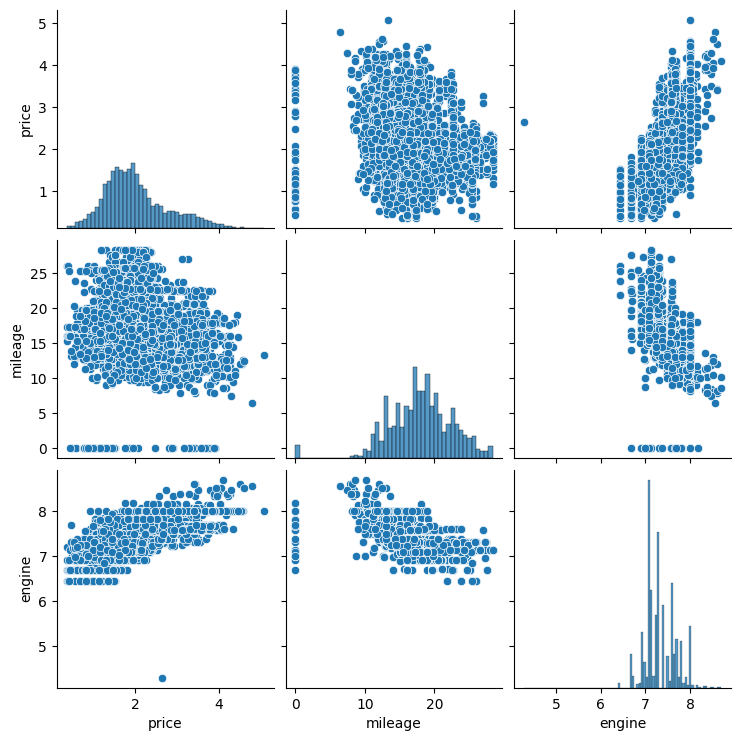

In [93]:
sns.pairplot(df[['price', 'mileage', 'engine', 'power']])
diag_kind='kde'

<Axes: xlabel='fuel_type', ylabel='price'>

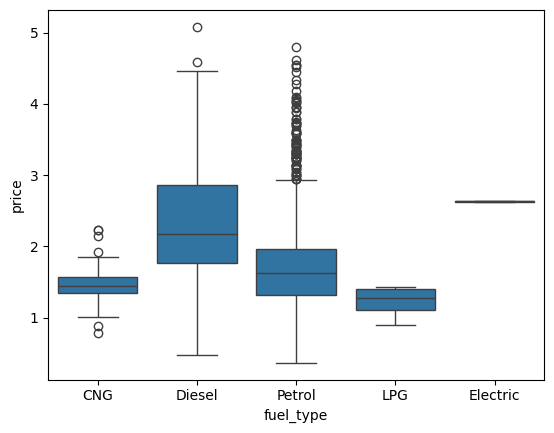

In [94]:
sns.boxplot(data=df, x="fuel_type", y="price")

<Axes: xlabel='transmission', ylabel='price'>

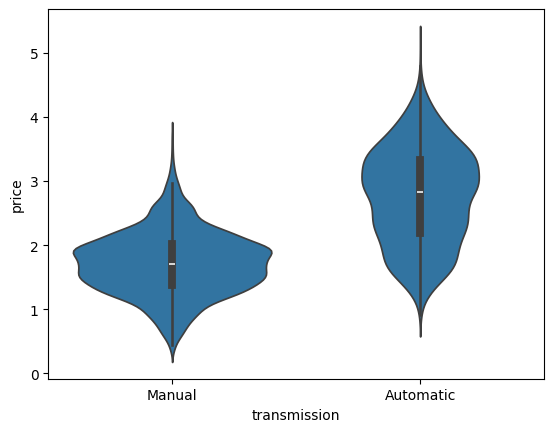

In [95]:
sns.violinplot(data=df, x="transmission", y="price")

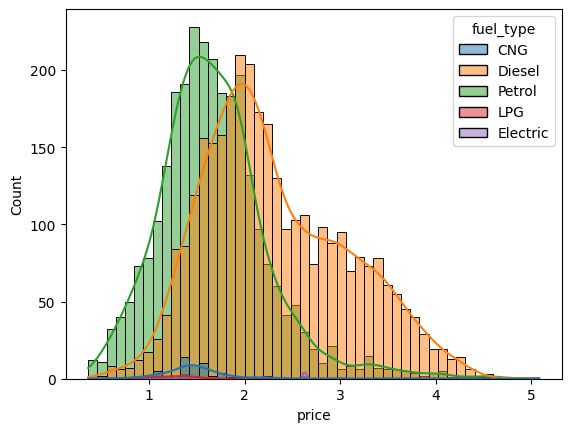

In [97]:
sns.histplot(data = df, x = 'price', hue = 'fuel_type', kde = True)
plt.show()

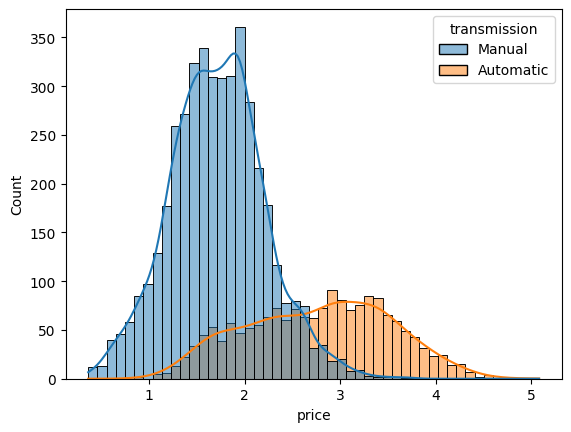

In [98]:
sns.histplot(data = df, x = 'price', hue = 'transmission', kde = True)
plt.show()

<Axes: xlabel='fuel_type', ylabel='price'>

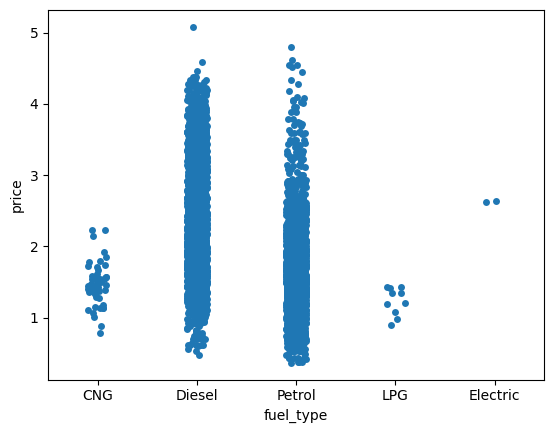

In [99]:
sns.stripplot(x="fuel_type", y = 'price', data=df, jitter = True)